# 기준 CNN

# FoldedVision AI — Ring 결함 검사
수업의 데이터 확인 → 전처리 → 모델 구성 → compile → fit → 평가 순서를 따른다.
1112_김현모_0.8045.ipynb의 단계별 설명과 05.ipynb의 CNN을 출발점으로 삼았다.
추가 개념은 **검증 데이터, BatchNormalization, 클래스 불균형, U-Net**이다.

**데이터로 말할 수 있는 범위:** 정상 라벨이 확인되지 않으면 정상/불량 판정을 하지 않는다.
결함 유형 분류의 Softmax는 이미 결함이 있는 표본 안에서의 유형 점수다.
정상일 확률이나 불량일 확률로 해석할 수 없다.

In [1]:
# PART 01. 실행 설정 — 수정할 값은 이 셀에 모은다.
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("OMP_NUM_THREADS", "4")
from pathlib import Path
DATASET_NAME = "Ring"
IMAGE_SIZE = 256
BATCH_SIZE = 16
SEED = 42
RUN_MODE = os.environ.get("RING_RUN_MODE", "full")
TRAIN_IMPROVED_CNN = True
TRAIN_UNET = True
TRAIN_AUTOENCODER = False
USE_SAVED_MODELS = True
LAUNCH_UI = False
TARGET_RECALL = 0.95
MIN_LOCALIZATION_VALID_DICE = 0.10  # 시연에서 마스크를 제공할 최소 검증 품질
BASELINE_EPOCHS = 20 if RUN_MODE == "full" else 2
CNN_EPOCHS = 24 if RUN_MODE == "full" else 2
UNET_EPOCHS = 12 if RUN_MODE == "full" else 2
assert RUN_MODE in ("quick", "full")
assert IMAGE_SIZE >= 64 and IMAGE_SIZE % 8 == 0
project_start = Path.cwd().resolve()
PROJECT_ROOT = next((folder for folder in (project_start, *project_start.parents)
                     if (folder / "requirements-lock.txt").is_file()
                     and (folder / "AGENTS.md").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the FoldedVision_AI project.")
OUT = PROJECT_ROOT / "outputs"
MODELS = PROJECT_ROOT / "models"
if RUN_MODE == "quick":
    OUT = OUT / "quick"
    MODELS = MODELS / "quick"
for folder in [MODELS, OUT / "figures", OUT / "metrics",
               OUT / "predictions", OUT / "integration", PROJECT_ROOT / "data/processed"]:
    folder.mkdir(parents=True, exist_ok=True)
print("실행 모드:", RUN_MODE, "| 이미지 크기:", IMAGE_SIZE)
# 새 요청: 다운로드한 베어링 16종 자료 별도 학습
BR_IMAGE_SIZE = 192
BR_BATCH_SIZE = 32
BR_SEED = 42
BR_EPOCHS = 70 if RUN_MODE == "full" else 2
LAUNCH_BEARING_UI = False


실행 모드: full | 이미지 크기: 256


In [2]:
# 라이브러리와 CPU/GPU 확인
import sys, json, tarfile, hashlib, time, shutil
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    roc_curve, roc_auc_score, average_precision_score)
from IPython.display import display
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass
plt.rcParams["font.family"] = "Malgun Gothic" if sys.platform == "win32" else "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
print("Python:", sys.version.split()[0], "TensorFlow:", tf.__version__)
print("사용 가능한 GPU:", tf.config.list_physical_devices("GPU"))

Python: 3.11.9 TensorFlow: 2.15.0
사용 가능한 GPU: []


In [3]:
# JSON과 그림 저장 — NaN 대신 null을 사용하여 다른 팀도 읽을 수 있게 한다.
def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2,
                                    allow_nan=False), encoding="utf-8")
def save_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()
def read_rgb(path):
    # Windows 한글 경로도 읽을 수 있도록 imdecode를 사용한다.
    bgr = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"이미지를 읽을 수 없습니다: {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

## PART 01. 데이터 준비와 라벨 검증
inference를 정상 데이터로 간주하지 않는다. SHA-256 중복 검사 후 같은 분할을 재현한다.

In [4]:
# Ring만 찾는다. 다른 부품 데이터는 변경하지 않는다.
def find_ring():
    for folder in [PROJECT_ROOT / "data/raw/Ring", PROJECT_ROOT / "data/Ring", PROJECT_ROOT / "Ring"]:
        if (folder / "train/_annotations.coco.json").is_file():
            return folder
    searches = [PROJECT_ROOT, PROJECT_ROOT / "data", PROJECT_ROOT / "data/archives",
                PROJECT_ROOT / "data/raw", Path.home() / "Downloads"]
    archive = next((p / "Ring.tar.gz" for p in searches if (p / "Ring.tar.gz").is_file()), None)
    if archive is None:
        raise FileNotFoundError("Ring.tar.gz를 data/archives/에 넣어 주세요.")
    target = (PROJECT_ROOT / "data/raw").resolve()
    target.mkdir(parents=True, exist_ok=True)
    with tarfile.open(archive, "r:gz") as tar:
        for member in tar.getmembers():
            relative = Path(member.name)
            destination = (target / relative).resolve()
            if (relative.is_absolute() or not destination.is_relative_to(target)
                or not relative.parts or relative.parts[0] != "Ring"):
                raise ValueError(f"안전하지 않은 압축 경로: {member.name}")
            if member.issym() or member.islnk() or not (member.isfile() or member.isdir()):
                raise ValueError(f"허용하지 않는 압축 항목: {member.name}")
            if relative.name.startswith("._") or "__MACOSX" in relative.parts:
                continue
            if member.isdir():
                destination.mkdir(parents=True, exist_ok=True)
            elif not destination.exists():
                destination.parent.mkdir(parents=True, exist_ok=True)
                with tar.extractfile(member) as src, destination.open("wb") as dst:
                    shutil.copyfileobj(src, dst)
    return target / "Ring"
DATA_ROOT = find_ring()
print("원본 데이터:", DATA_ROOT)

원본 데이터: C:\Users\kdt66\Desktop\FoldedVision_AI\data\raw\Ring


In [5]:
# COCO의 images, annotations, categories를 실제로 연결한다.
coco = {}
records, objects = [], []
annotations_by_key = {}
for official_split in ["train", "val", "inference"]:
    document = json.loads((DATA_ROOT / official_split / "_annotations.coco.json").read_text(encoding="utf-8"))
    coco[official_split] = document
    by_image = defaultdict(list)
    for annotation in document.get("annotations", []):
        by_image[annotation["image_id"]].append(annotation)
    for image in document["images"]:
        image_path = (DATA_ROOT / official_split / image["file_name"]).resolve()
        if not image_path.is_relative_to(DATA_ROOT.resolve()):
            raise ValueError("COCO 이미지 경로가 데이터 폴더 밖을 가리킵니다.")
        rgb = read_rgb(image_path)
        if rgb.shape[:2] != (image["height"], image["width"]):
            raise ValueError("COCO 크기와 실제 이미지 크기가 다릅니다.")
        key = f"{official_split}:{image['id']}"
        anns = by_image[image["id"]]
        annotations_by_key[key] = anns
        records.append(dict(image_id=key, path=str(image_path),
            official_split=official_split, width=rgb.shape[1], height=rgb.shape[0],
            extension=image_path.suffix.lower(), n_defects=len(anns),
            category_ids=sorted({a["category_id"] for a in anns}),
            sha256=hashlib.sha256(image_path.read_bytes()).hexdigest()))
        for a in anns:
            x, y, w, h = a["bbox"]
            objects.append(dict(image_id=key, official_split=official_split,
                category_id=a["category_id"], cx=(x+w/2)/rgb.shape[1],
                cy=(y+h/2)/rgb.shape[0], box_area=w*h/(rgb.shape[0]*rgb.shape[1]),
                polygon_area=a.get("area"), has_polygon=isinstance(a.get("segmentation"),list)
                and bool(a["segmentation"])))
images = pd.DataFrame(records)
annotations = pd.DataFrame(objects)
categories = sorted(coco["train"]["categories"], key=lambda c: c["id"])
CLASS_NAMES = [c["name"] for c in categories]
CLASS_KO = {"t_contamination": "오염", "t_scratch": "긁힘", "unfinished_surface": "표면 미가공"}
category_to_label = {c["id"]: i for i, c in enumerate(categories)}
print("결함 유형:", [(name, CLASS_KO.get(name, "원문 확인 필요")) for name in CLASS_NAMES])
display(images.groupby("official_split").agg(
    이미지수=("image_id","size"), 어노테이션없는이미지=("n_defects",lambda s:int((s==0).sum()))))

결함 유형: [('t_contamination', '오염'), ('t_scratch', '긁힘'), ('unfinished_surface', '표면 미가공')]


,이미지수,어노테이션없는이미지
official_split,,
inference,464,464
train,45,0
val,42,0


In [6]:
# 공식 카드: inference는 테스트+미사용 이미지이며 정답이 없다.
SOURCE_URL = "https://huggingface.co/datasets/VISION-Workshop/VISION-Datasets"
LABEL_REASON = ("공식 train/val의 모든 이미지에 결함 어노테이션이 있다. "
    "inference에는 정답이 없으므로 정상으로 사용할 수 없다. "
    "검증된 정상 표본이 없어 이진 분류와 제조 불량 감소율은 평가 불가.")
BINARY_SUPPORTED = False
labeled = images[images.official_split.isin(["train","val"])].copy()
assert labeled.category_ids.map(len).eq(1).all(), "다중 라벨 데이터: 별도 설계가 필요합니다."
labeled["label"] = labeled.category_ids.map(lambda ids: category_to_label[ids[0]])
labeled["defect_type"] = labeled.label.map(dict(enumerate(CLASS_NAMES)))
print(LABEL_REASON)
display(pd.crosstab(labeled.defect_type, labeled.official_split))
audit = dict(dataset="Ring", total_images=len(images), labeled_images=len(labeled),
    verified_normal_images=0, annotated_defect_images=len(labeled),
    unlabeled_images=int((images.official_split=="inference").sum()),
    class_names=CLASS_NAMES, source_url=SOURCE_URL, binary_supported=False,
    label_reason=LABEL_REASON, exact_duplicate_extra_images=int(images.sha256.duplicated().sum()),
    extensions=images.extension.value_counts().to_dict(),
    resolutions=images.groupby(["width","height"]).size().reset_index(name="count").to_dict("records"),
    bbox_count=len(annotations), polygon_count=int(annotations.has_polygon.sum()),
    source_note="공식 polygon은 원본 bbox를 보완한 라벨이며 정밀 제조 계측 정답이 아니다.")
save_json(OUT / "metrics/data_audit.json", audit)
images.drop(columns=["category_ids"]).to_csv(OUT / "metrics/image_inventory.csv",index=False)

공식 train/val의 모든 이미지에 결함 어노테이션이 있다. inference에는 정답이 없으므로 정상으로 사용할 수 없다. 검증된 정상 표본이 없어 이진 분류와 제조 불량 감소율은 평가 불가.


official_split,train,val
defect_type,,
t_contamination,13,15
t_scratch,25,23
unfinished_surface,7,4


In [7]:
# 공식 val은 최종 평가로 재지정. 공식 train 안에서만 학습/검증한다.
holdout = labeled[labeled.official_split=="val"].drop_duplicates("sha256").copy()
pool = labeled[(labeled.official_split=="train")
               & ~labeled.sha256.isin(holdout.sha256)].drop_duplicates("sha256").copy()
train, valid = train_test_split(pool, test_size=0.25, random_state=SEED, stratify=pool.label)
train, valid, holdout = [d.reset_index(drop=True) for d in (train, valid, holdout)]
for left, right in [(train, valid), (train, holdout), (valid, holdout)]:
    assert set(left.sha256).isdisjoint(right.sha256)
manifest = pd.concat([d.assign(split=name) for name,d in
                      [("train",train),("validation",valid),("holdout",holdout)]])
manifest.drop(columns=["category_ids"]).to_csv(OUT / "metrics/split_manifest.csv",index=False)
DATA_SIGNATURE = hashlib.sha256(manifest[["image_id","sha256","split"]]
    .to_csv(index=False).encode()).hexdigest()
print("학습 / 검증 / 최종 평가:", len(train), len(valid), len(holdout))
print("동일 바이트 중복은 분리 간 제거. 유사 촬영 이미지의 잔여 상관은 한계로 남는다.")

학습 / 검증 / 최종 평가:

 33 12 42
동일 바이트 중복은 분리 간 제거. 유사 촬영 이미지의 잔여 상관은 한계로 남는다.


## PART 02. 탐색적 분석 (EDA)
모델 선택 전에 분포를 확인한다. 최종 평가 이미지는 대표 샘플 선정에 쓰지 않는다.
정상 분포 대신 **정답 있는 결함 / 라벨 미공개**를 구분한다.

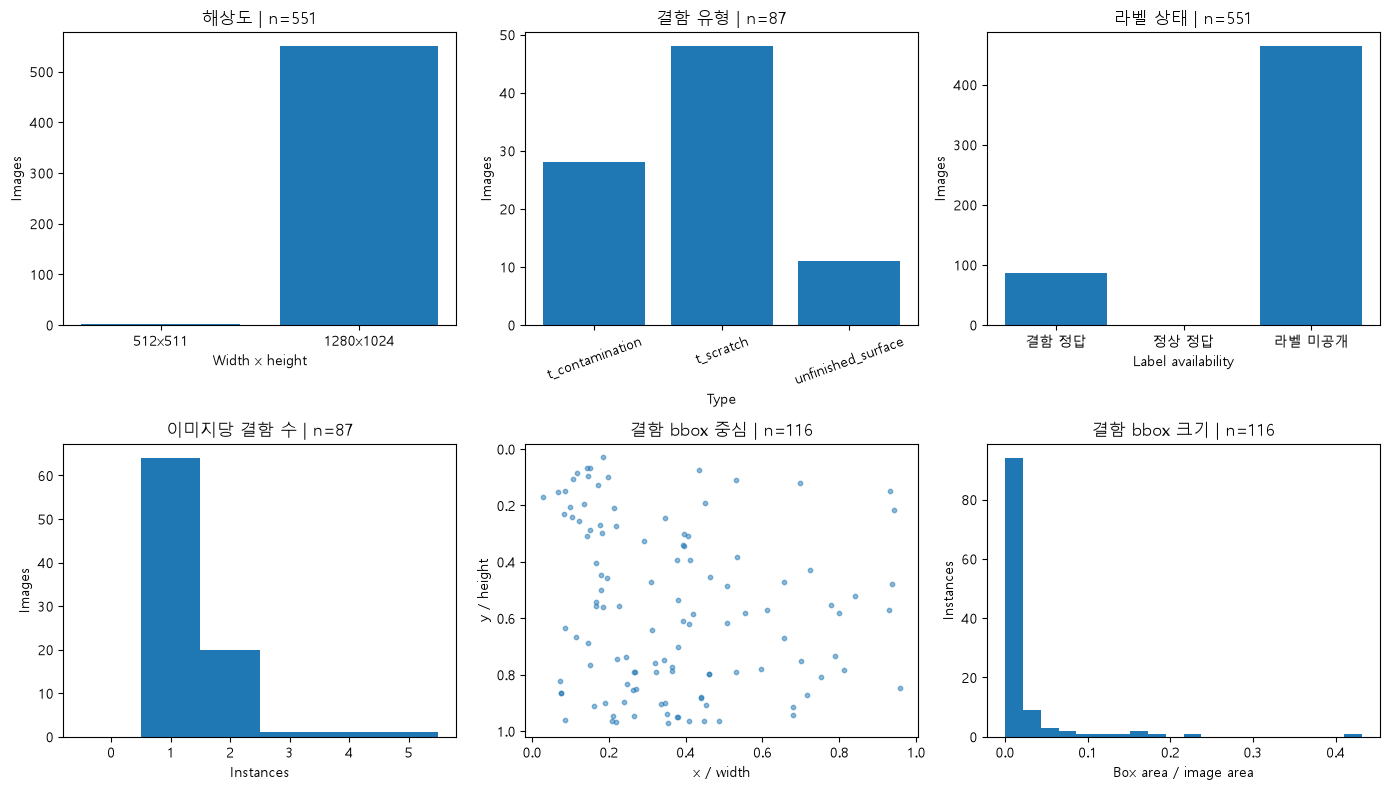

In [8]:
fig,axes=plt.subplots(2,3,figsize=(14,8))
res=images.groupby(["width","height"]).size()
axes[0,0].bar([f"{w}x{h}" for w,h in res.index],res.values)
axes[0,0].set(title=f"해상도 | n={len(images)}",xlabel="Width x height",ylabel="Images")
counts=labeled.defect_type.value_counts().reindex(CLASS_NAMES,fill_value=0)
axes[0,1].bar(counts.index,counts.values)
axes[0,1].tick_params(axis="x",rotation=20)
axes[0,1].set(title=f"결함 유형 | n={len(labeled)}",xlabel="Type",ylabel="Images")
axes[0,2].bar(["결함 정답","정상 정답","라벨 미공개"],[len(labeled),0,int((images.official_split=="inference").sum())])
axes[0,2].set(title=f"라벨 상태 | n={len(images)}",xlabel="Label availability",ylabel="Images")
axes[1,0].hist(labeled.n_defects,bins=np.arange(labeled.n_defects.max()+2)-0.5)
axes[1,0].set(title=f"이미지당 결함 수 | n={len(labeled)}",xlabel="Instances",ylabel="Images")
axes[1,1].scatter(annotations.cx,annotations.cy,s=10,alpha=0.5)
axes[1,1].invert_yaxis()
axes[1,1].set(title=f"결함 bbox 중심 | n={len(annotations)}",xlabel="x / width",ylabel="y / height")
axes[1,2].hist(annotations.box_area,bins=20)
axes[1,2].set(title=f"결함 bbox 크기 | n={len(annotations)}",xlabel="Box area / image area",ylabel="Instances")
save_figure("ring_eda")

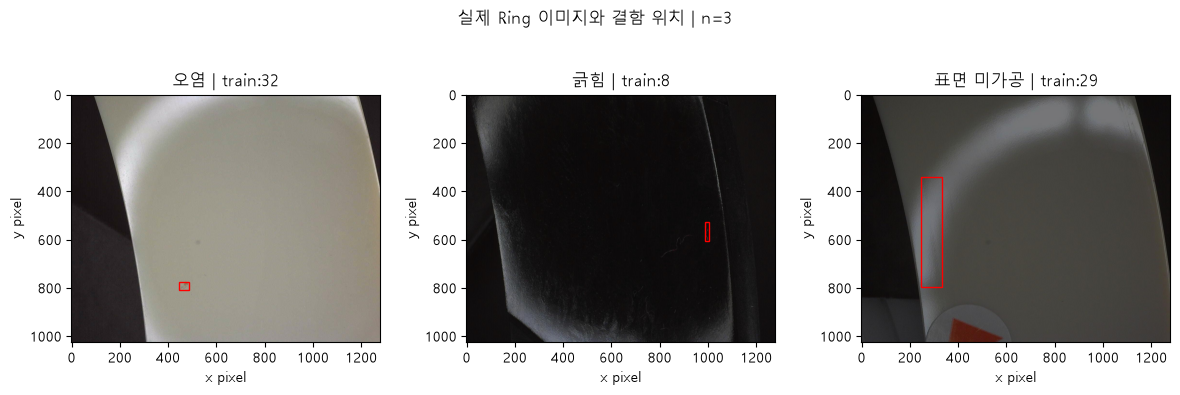

In [9]:
# 학습 표본마다 실제 bounding box를 그려서 라벨 연결을 확인한다.
fig,axes=plt.subplots(1,3,figsize=(12,4))
for label,ax in enumerate(axes):
    row=train[train.label==label].iloc[0]
    ax.imshow(read_rgb(row.path))
    for a in annotations_by_key[row.image_id]:
        x,y,w,h=a["bbox"]
        ax.add_patch(matplotlib.patches.Rectangle((x,y),w,h,fill=False,edgecolor="red",linewidth=1))
    ax.set_title(f"{CLASS_KO[CLASS_NAMES[label]]} | {row.image_id}")
    ax.set(xlabel="x pixel",ylabel="y pixel")
fig.suptitle("실제 Ring 이미지와 결함 위치 | n=3")
save_figure("ring_samples")

## PART 03. 입력 준비
0~255 픽셀을 0~1로 변환한다. 표 형태 실습의 MinMaxScaler와 달리 고정된 255로 나눈다.

In [10]:
# PART 03. OpenCV 전처리 — 색상 정보와 작은 결함을 보존한다.
def preprocess(rgb, method="rgb", size=IMAGE_SIZE):
    image = rgb.copy()
    if method == "clahe":
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        lab[:,:,0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(lab[:,:,0])
        image = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    elif method == "denoise":
        image = cv2.GaussianBlur(image, (3,3), 0)
    elif method != "rgb":
        raise ValueError(f"지원하지 않는 전처리: {method}")
    # 전체 프레임을 유지하여 ROI 밖의 결함이 잘리는 것을 피한다.
    image = cv2.resize(image, (size,size), interpolation=cv2.INTER_AREA)
    return image.astype("float32") / 255.0
def load_xy(frame, method="rgb"):
    x = np.stack([preprocess(read_rgb(p), method) for p in frame.path])
    return x, frame.label.to_numpy(dtype="int32")


In [11]:
X_train, y_train = load_xy(train)
X_valid, y_valid = load_xy(valid)
print("입력:", X_train.shape, "| 정답:", y_train.shape)

입력: (33, 256, 256, 3) | 정답: (33,)


In [12]:
# 수업의 Sequential / Conv2D / Pooling / Dense를 확장한다.
def build_cnn(improved=False):
    model = keras.Sequential(name="ring_improved" if improved else "ring_baseline")
    model.add(keras.Input(shape=(IMAGE_SIZE,IMAGE_SIZE,3)))
    if improved:
        # fit 중에만 증강한다. 검증/평가/추론에는 증강하지 않는다.
        model.add(layers.RandomFlip("horizontal_and_vertical", seed=SEED))
        model.add(layers.RandomRotation(0.04, fill_mode="reflect", seed=SEED))
    for filters in [32,64,128]:
        model.add(layers.Conv2D(filters, 3, padding="same",
                               activation=None if improved else "relu"))
        if improved:
            model.add(layers.BatchNormalization())
            model.add(layers.Activation("relu"))
            if filters == 32:
                model.add(layers.Conv2D(filters,3,padding="same",activation="relu"))
        if filters != 128:
            model.add(layers.MaxPooling2D())
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(64,activation="relu"))
    if improved:
        model.add(layers.Dropout(0.35))
    model.add(layers.Dense(len(CLASS_NAMES),activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005 if improved else 0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

In [13]:
# 캐시는 같은 데이터 분할·설정일 때만 재사용한다.
def train_cnn(name, method="rgb", improved=False):
    epochs = CNN_EPOCHS if improved else BASELINE_EPOCHS
    signature = dict(data_signature=DATA_SIGNATURE, image_size=IMAGE_SIZE, seed=SEED,
        batch_size=BATCH_SIZE, epochs=epochs, method=method, improved=improved,
        run_mode=RUN_MODE, classes=CLASS_NAMES, architecture_version=1)
    path = MODELS / f"{name}.keras"
    meta_path = MODELS / f"{name}.json"
    if USE_SAVED_MODELS and path.exists() and meta_path.exists():
        metadata = json.loads(meta_path.read_text(encoding="utf-8"))
        if metadata["signature"] == signature:
            return keras.models.load_model(path), metadata
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_cnn(improved)
    xtr, ytr = load_xy(train,method)
    xv, yv = load_xy(valid,method)
    counts = np.bincount(ytr,minlength=len(CLASS_NAMES))
    weights = {i:len(ytr)/(len(CLASS_NAMES)*int(n)) for i,n in enumerate(counts)}
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss",patience=6,restore_best_weights=True),
                 keras.callbacks.ModelCheckpoint(str(path),monitor="val_loss",save_best_only=True)]
    start = time.perf_counter()
    history = model.fit(xtr,ytr,validation_data=(xv,yv),epochs=epochs,
        batch_size=BATCH_SIZE, class_weight=weights if improved else None,
        callbacks=callbacks,verbose=2)
    model = keras.models.load_model(path)
    metadata = dict(signature=signature,history=history.history,
        train_seconds=time.perf_counter()-start,parameters=model.count_params(),
        actual_epochs=len(history.history["loss"]))
    save_json(meta_path, metadata)
    return model, metadata
def plot_history(metadata, name):
    fig, axes = plt.subplots(1,2,figsize=(10,3.5))
    for ax,metric in zip(axes,["loss","accuracy"]):
        ax.plot(metadata["history"][metric],label="train")
        ax.plot(metadata["history"]["val_"+metric],label="validation")
        ax.set(xlabel="Epoch",ylabel=metric,title=f"{name} | n={len(train)}/{len(valid)}")
        ax.legend()
    save_figure(name+"_history")

In [14]:
# 다중 분류 지표와 이진 검사 지표를 구분한다.
def evaluate_types(model, frame, method, name):
    x,y = load_xy(frame,method)
    model(x[:1],training=False)
    start = time.perf_counter()
    probabilities = model.predict(x,batch_size=BATCH_SIZE,verbose=0)
    ms = (time.perf_counter()-start)*1000/len(x)
    pred = probabilities.argmax(axis=1)
    report = classification_report(y,pred,labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,zero_division=0,output_dict=True)
    metrics = dict(task="defect_type_multiclass",run_mode=RUN_MODE,n=len(y),
        accuracy=float(accuracy_score(y,pred)),
        macro_f1=float(f1_score(y,pred,labels=list(range(len(CLASS_NAMES))),
                              average="macro",zero_division=0)),
        class_report=report,mean_inference_ms=ms,parameters=model.count_params())
    save_json(OUT / "metrics" / f"{name}_metrics.json",metrics)
    return metrics, probabilities
def plot_classification(frame, probabilities, name):
    y = frame.label.to_numpy()
    pred = probabilities.argmax(1)
    fig,ax=plt.subplots(figsize=(6,5))
    ConfusionMatrixDisplay.from_predictions(y,pred,labels=range(len(CLASS_NAMES)),
        display_labels=CLASS_NAMES,xticks_rotation=25,ax=ax,colorbar=False)
    ax.set_title(f"{name}: 결함 유형 혼동행렬 | n={len(y)}")
    save_figure(name+"_confusion")
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for i,name_i in enumerate(CLASS_NAMES):
        binary=(y==i).astype(int)
        if len(np.unique(binary))<2:
            continue
        fpr,tpr,_=roc_curve(binary,probabilities[:,i])
        pr,rec,_=precision_recall_curve(binary,probabilities[:,i])
        axes[0].plot(fpr,tpr,label=f"{name_i}: {roc_auc_score(binary,probabilities[:,i]):.3f}")
        axes[1].plot(rec,pr,label=f"{name_i}: {average_precision_score(binary,probabilities[:,i]):.3f}")
    axes[0].set(xlabel="FPR",ylabel="TPR",title=f"유형별 one-vs-rest ROC | n={len(y)}")
    axes[1].set(xlabel="Recall",ylabel="Precision",title=f"유형별 one-vs-rest PR | n={len(y)}")
    for ax in axes: ax.legend(fontsize=8)
    save_figure(name+"_roc_pr")
    wrong=np.flatnonzero(pred!=y)[:6]
    if len(wrong):
        fig,axes=plt.subplots(1,len(wrong),figsize=(3*len(wrong),3),squeeze=False)
        for ax,j in zip(axes[0],wrong):
            ax.imshow(read_rgb(frame.iloc[j].path))
            ax.set_title(f"정답: {CLASS_KO[CLASS_NAMES[y[j]]]}\n예측: {CLASS_KO[CLASS_NAMES[pred[j]]]}")
            ax.axis("off")
        save_figure(name+"_type_errors")

## PART 04~05. 기준 CNN 학습
합성곱은 작은 영역의 특징을 찾고, Pooling은 특징 맵을 줄인다.
GlobalAveragePooling은 특징 채널별 평균을 사용한다.
정답을 정수 0/1/2로 두므로 sparse categorical crossentropy를 쓴다.
검증 손실이 좋아지는 모델을 저장하고, 과적합이 계속되면 일찍 멈춘다.

Model: "ring_baseline"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 conv2d (Conv2D)             (None, 256, 256, 32)      896       


 max_pooling2d (MaxPooling2  (None, 128, 128, 32)      0         


 D)                                                              


... (8 outputs left out)

Total params: 101699 (397.26 KB)


Trainable params: 101699 (397.26 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


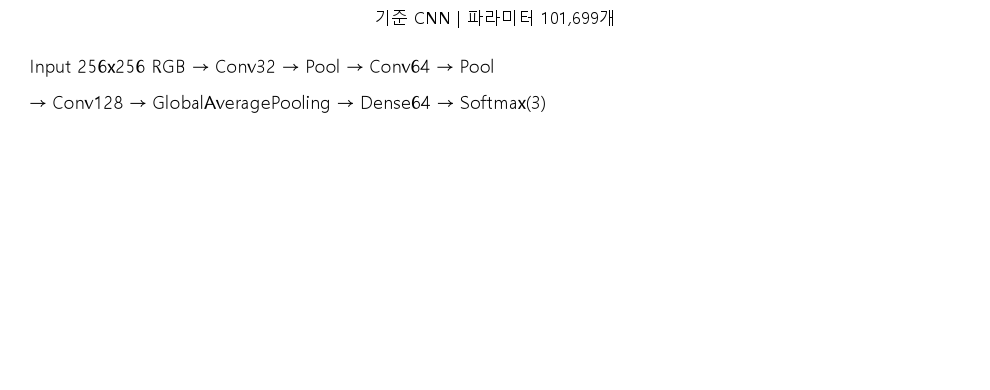

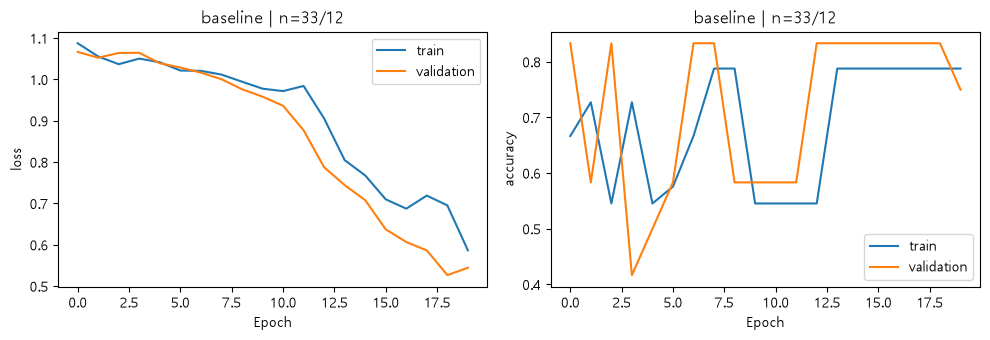

In [15]:
baseline, baseline_metadata = train_cnn("ring_cnn_baseline")
baseline.summary()
summary=[]
baseline.summary(print_fn=summary.append)
(OUT / "metrics/baseline_architecture.txt").write_text("\n".join(summary),encoding="utf-8")
fig,ax=plt.subplots(figsize=(10,4))
ax.axis("off")
ax.text(0.02,0.95,"Input 256x256 RGB → Conv32 → Pool → Conv64 → Pool\n"
        "→ Conv128 → GlobalAveragePooling → Dense64 → Softmax(3)",
        va="top",fontsize=13,linespacing=2)
ax.set_title(f"기준 CNN | 파라미터 {baseline.count_params():,}개")
save_figure("baseline_architecture")
plot_history(baseline_metadata, "baseline")

## PART 06. 최종 홀드아웃 평가
공식 val 42장을 최종 평가로 재지정했다. 이 점수로 전처리나 모델을 선택하지 않는다.
유형 오분류는 정상/불량의 FP/FN과 다르다. 유형별 ROC/PR 역시 정상/불량 곡선이 아니다.

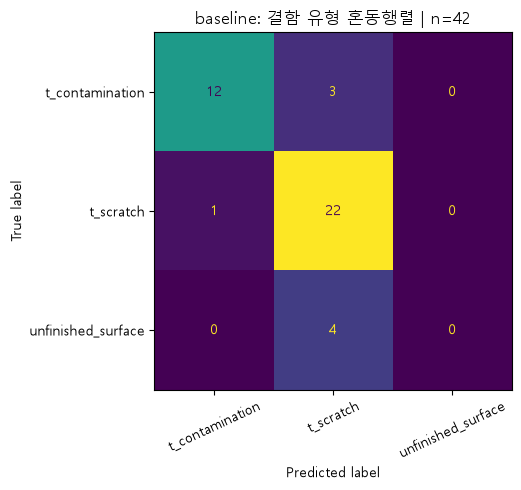

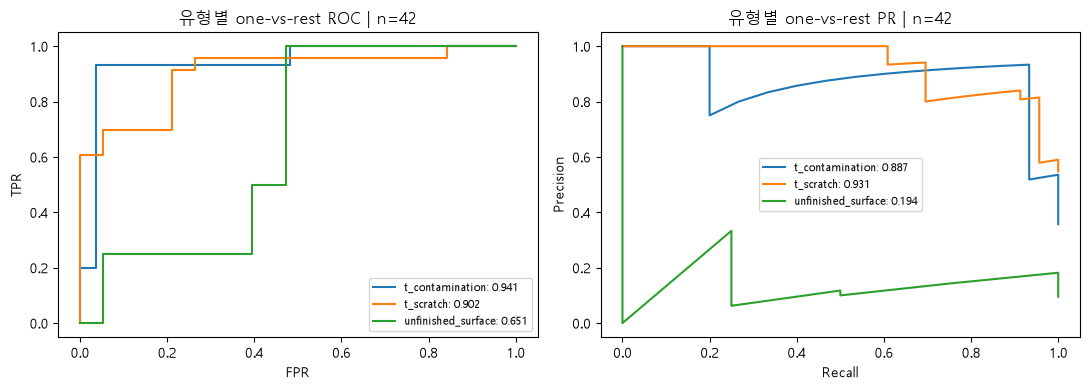

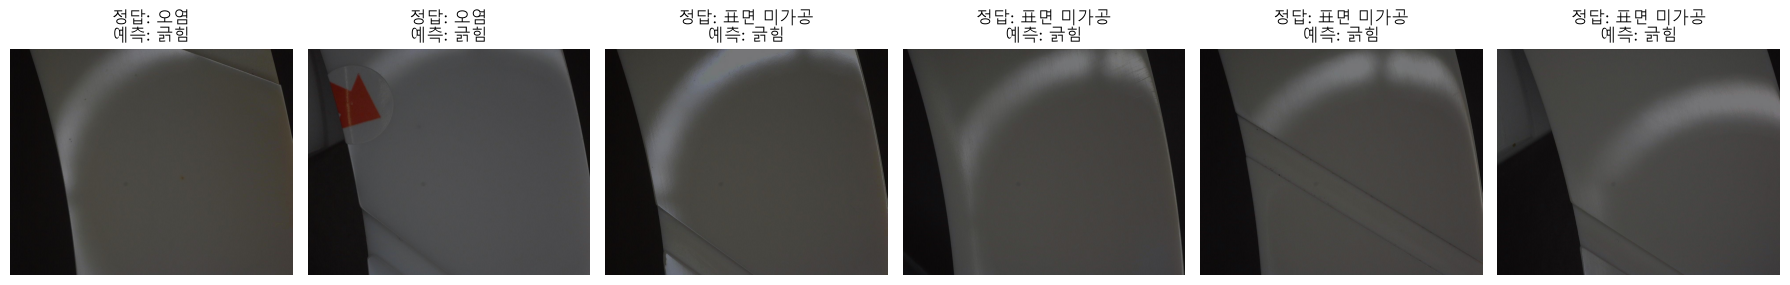

In [16]:
baseline_validation, _ = evaluate_types(baseline,valid,"rgb","baseline_validation")
baseline_metrics, baseline_probabilities = evaluate_types(baseline,holdout,"rgb","ring_baseline")
baseline_metrics.update(train_images=len(train),validation_images=len(valid),
    evaluation_images=len(holdout),binary_supported=False,binary_recall=None,
    train_seconds=baseline_metadata["train_seconds"],data_signature=DATA_SIGNATURE)
save_json(OUT / "metrics/ring_baseline_metrics.json",baseline_metrics)
plot_classification(holdout,baseline_probabilities,"baseline")
pd.DataFrame(baseline_metrics["class_report"]).T.to_csv(OUT / "metrics/baseline_class_report.csv")

## PART 07. 실제 결과 요약

In [17]:
print(f"모드: {RUN_MODE}")
print(f"기준 CNN 정확도: {baseline_metrics['accuracy']:.4f}")
print(f"기준 CNN Macro F1: {baseline_metrics['macro_f1']:.4f}")
print("검증 정확도와 최종 평가 정확도는 서로 다른 표본에서 계산했다.")
print("한계:",LABEL_REASON)
print("수업 연결: Dense/Dropout → Conv2D/Pooling → 검증 분리와 학습 중단 추가")

모드: full
기준 CNN 정확도: 0.8095
기준 CNN Macro F1: 0.5678
검증 정확도와 최종 평가 정확도는 서로 다른 표본에서 계산했다.
한계: 공식 train/val의 모든 이미지에 결함 어노테이션이 있다. inference에는 정답이 없으므로 정상으로 사용할 수 없다. 검증된 정상 표본이 없어 이진 분류와 제조 불량 감소율은 평가 불가.
수업 연결: Dense/Dropout → Conv2D/Pooling → 검증 분리와 학습 중단 추가


## 다운로드한 자료 실제 학습 — 엔진 베어링 설치 상태 16종
사용자의 후속 요청에 따라 Data.zip으로 별도 학습한다. 숫자 1~16은 설치 상태 조합 ID다.
수업의 데이터 확인 → 분할 → CNN → 학습 → 평가 흐름을 사용한다.
좌우 반전은 설치 위치 의미를 바꿀 수 있어 사용하지 않는다.
이 작업의 정확도와 VISION Ring 3종의 80.95%는 서로 다른 평가다.
이 절만 실행하려면 settings / environment / io 태그 셀 뒤에 bearing_* 태그 셀을 순서대로 실행한다.

In [4]:
BR_SOURCE=PROJECT_ROOT/"data/external/user_drive_bearing/Data"
BR_OUT=OUT/"bearing_installation"
BR_MODELS=MODELS/"bearing_installation"
BR_CACHE=PROJECT_ROOT/"data/processed/bearing_installation"
for folder in [BR_OUT,BR_MODELS,BR_CACHE,BR_OUT/"figures"]:
    folder.mkdir(parents=True,exist_ok=True)
BR_CLASS_IDS=list(range(1,17))
BR_CLASS_NAMES=[f"installation_{i:02d}" for i in BR_CLASS_IDS]
print("실제 학습 자료:",BR_SOURCE)
print("작업: 엔진 베어링 설치 상태 16종 / 모드:",RUN_MODE)

실제 학습 자료: C:\Users\kdt66\Desktop\FoldedVision_AI\data\external\user_drive_bearing\Data
작업: 엔진 베어링 설치 상태 16종 / 모드: full


In [5]:
# 사진 해시와 파일명 번호를 검사한다. 원본 validation은 최종 평가로 남긴다.
import re
from PIL import Image
br_rows=[]
for source_split in ["Classification Train","Classification Validation"]:
    for path in sorted((BR_SOURCE/source_split).glob("*/*.jpg")):
        class_id=int(path.parent.name)
        capture=int(re.search(r"(\d+)\.[^.]+$",path.name).group(1))
        with Image.open(path) as image:
            width,height=image.size
        br_rows.append(dict(path=str(path),class_id=class_id,label=class_id-1,
            source_split=source_split,capture=capture,width=width,height=height,
            sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
            capture_group=f"{class_id}:{(capture-1)//5}"))
br_frame=pd.DataFrame(br_rows)
assert set(br_frame.class_id)==set(BR_CLASS_IDS)
conflicts=br_frame.groupby("sha256").label.nunique()
conflicting_hashes=set(conflicts[conflicts>1].index)
if conflicting_hashes:
    raise ValueError(f"동일 사진의 설치 상태 라벨 충돌: {len(conflicting_hashes)}건")
br_test=br_frame[br_frame.source_split=="Classification Validation"].drop_duplicates("sha256").copy()
br_pool=br_frame[(br_frame.source_split=="Classification Train")
    & ~br_frame.sha256.isin(br_test.sha256)
    & ~br_frame.capture_group.isin(br_test.capture_group)].drop_duplicates("sha256").copy()
# 클래스마다 촬영 번호 5장 블록의 20%를 내부 검증으로 고정한다.
rng=np.random.default_rng(BR_SEED)
validation_groups=set()
for label,part in br_pool.groupby("label",sort=True):
    groups=sorted(part.capture_group.unique())
    if len(groups)<3:raise ValueError("독립 번호 블록이 부족합니다.")
    chosen_groups=rng.permutation(groups)[:max(1,round(len(groups)*0.2))]
    validation_groups.update(chosen_groups)
br_valid=br_pool[br_pool.capture_group.isin(validation_groups)].copy()
br_train=br_pool[~br_pool.capture_group.isin(validation_groups)].copy()
for a,b in [(br_train,br_valid),(br_train,br_test),(br_valid,br_test)]:
    assert set(a.sha256).isdisjoint(b.sha256)
    assert set(a.capture_group).isdisjoint(b.capture_group)
for frame in [br_train,br_valid,br_test]:
    assert set(frame.label)==set(range(16))
br_manifest=pd.concat([part.assign(split=name) for name,part in
                      [("train",br_train),("validation",br_valid),("holdout",br_test)]])
br_manifest.to_csv(BR_OUT/"split_manifest.csv",index=False)
BR_DATA_SIGNATURE=hashlib.sha256(br_manifest[["sha256","label","split","capture_group"]]
    .to_csv(index=False).encode()+str(BR_IMAGE_SIZE).encode()).hexdigest()
br_audit=dict(task="bearing_installation_16class",total_images=len(br_frame),
    original_train=int((br_frame.source_split=="Classification Train").sum()),
    original_validation=int((br_frame.source_split=="Classification Validation").sum()),
    exact_duplicate_extra=int(br_frame.sha256.duplicated().sum()),
    excluded_train=len(br_frame[br_frame.source_split=="Classification Train"])-len(br_pool),
    train_images=len(br_train),validation_images=len(br_valid),evaluation_images=len(br_test),
    classes=BR_CLASS_NAMES,verified_normal_defect_mapping=False,
    group_policy="같은 클래스의 파일명 번호 5장 블록. 실제 부품/촬영 세션 ID는 제공되지 않음.",
    limitations=["동일 엔진 고정 장면의 설치 조합 분류","새 엔진/공장 일반화 미검증",
                 "번호 블록은 촬영 연속성 누수 완화를 위한 가정","기존 Ring 3종과 직접 성능 비교 불가"])
save_json(BR_OUT/"data_audit.json",br_audit)
display(pd.crosstab(br_manifest.class_id,br_manifest.split))
print("학습/검증/평가:",len(br_train),len(br_valid),len(br_test))

split,holdout,train,validation
class_id,,,
1,39,49,10
2,39,50,10
3,40,50,10
4,40,50,10
5,40,50,10
6,40,50,10
7,40,24,4
8,40,50,10
9,40,50,10


학습/검증/평가: 773 154 638


학습 배열: (773, 192, 192, 3) uint8


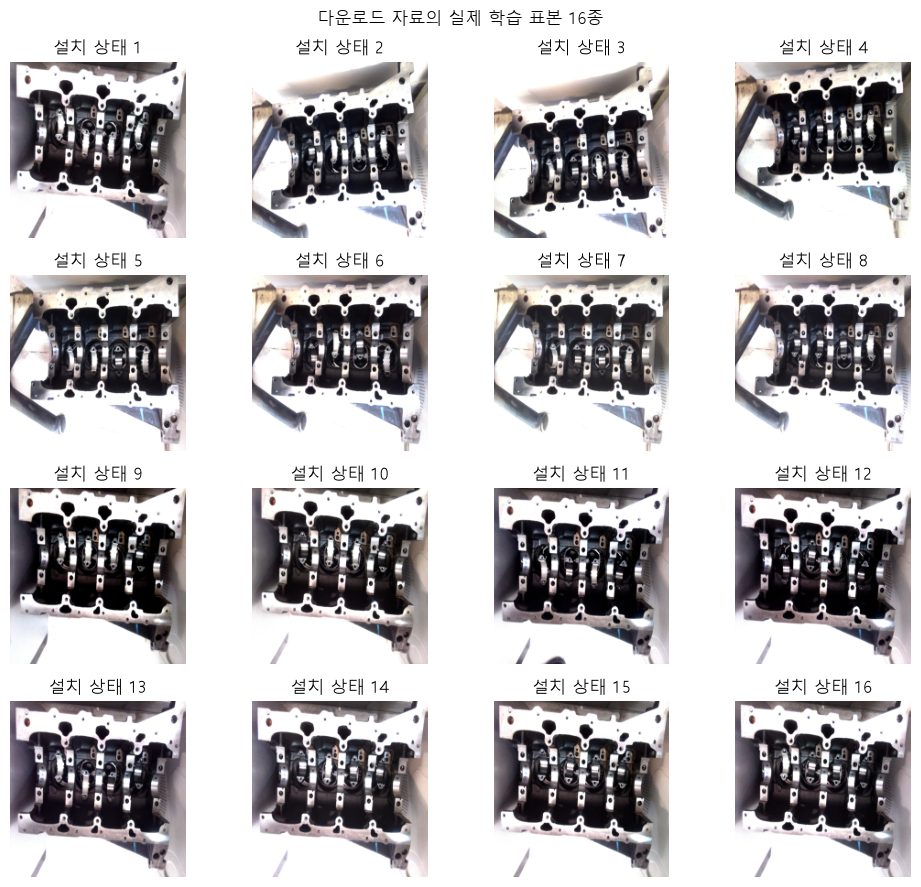

In [6]:
# 큰 원본은 JPEG 축소 디코딩 후 192 입력으로 만든다. 정답 위치를 사용하지 않는다.
def br_read_image(path):
    bgr=cv2.imdecode(np.fromfile(str(path),np.uint8),cv2.IMREAD_REDUCED_COLOR_4)
    if bgr is None:raise ValueError(f"이미지 읽기 실패: {path}")
    rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
    return cv2.resize(rgb,(BR_IMAGE_SIZE,BR_IMAGE_SIZE),interpolation=cv2.INTER_AREA)

br_cache_path=BR_CACHE/f"images_{BR_DATA_SIGNATURE[:16]}.npz"
if br_cache_path.exists():
    with np.load(br_cache_path) as arrays:
        BR_X_TRAIN=arrays["train"];BR_X_VALID=arrays["validation"];BR_X_TEST=arrays["holdout"]
else:
    BR_X_TRAIN=np.stack([br_read_image(path) for path in br_train.path])
    BR_X_VALID=np.stack([br_read_image(path) for path in br_valid.path])
    BR_X_TEST=np.stack([br_read_image(path) for path in br_test.path])
    np.savez_compressed(br_cache_path,train=BR_X_TRAIN,validation=BR_X_VALID,holdout=BR_X_TEST)
BR_Y_TRAIN=br_train.label.to_numpy(dtype="int32")
BR_Y_VALID=br_valid.label.to_numpy(dtype="int32")
BR_Y_TEST=br_test.label.to_numpy(dtype="int32")
print("학습 배열:",BR_X_TRAIN.shape,BR_X_TRAIN.dtype)
fig,axes=plt.subplots(4,4,figsize=(10,9))
for label,ax in enumerate(axes.flat):
    index=int(np.flatnonzero(BR_Y_TRAIN==label)[0])
    ax.imshow(BR_X_TRAIN[index]);ax.set_title(f"설치 상태 {label+1}");ax.axis("off")
fig.suptitle("다운로드 자료의 실제 학습 표본 16종")
plt.tight_layout();plt.savefig(BR_OUT/"figures/training_samples.png",dpi=140);plt.show();plt.close()

### CNN 구성과 학습
기준 모델은 특징 채널 평균(GAP)을 쓴다. 개선 모델은 Flatten으로 어느 위치의 특징인지 보존한다.
네 위치의 설치 조합을 구분하는 문제에서는 위치 정보가 중요하다.
증강 후보도 작은 이동·회전·밝기 변화만 사용하며, 좌우 반전을 하지 않는다.

In [7]:
def build_bearing_cnn(spatial=False,augment=False):
    inputs=keras.Input((BR_IMAGE_SIZE,BR_IMAGE_SIZE,3),name="rgb_uint8")
    x=layers.Rescaling(1.0/255)(inputs)
    if augment:
        x=layers.RandomTranslation(0.06,0.06,fill_mode="reflect",seed=BR_SEED)(x)
        x=layers.RandomRotation(0.025,fill_mode="reflect",seed=BR_SEED)(x)
        x=layers.RandomContrast(0.15,seed=BR_SEED)(x)
    for index,filters in enumerate([16,32,64]):
        x=layers.Conv2D(filters,5 if index==0 else 3,strides=2 if index==0 else 1,
                        padding="same",activation="relu")(x)
        if spatial:
            x=layers.Conv2D(filters,3,padding="same",activation="relu")(x)
        x=layers.MaxPooling2D()(x)
    x=layers.Flatten()(x) if spatial else layers.GlobalAveragePooling2D()(x)
    x=layers.Dense(128 if spatial else 64,activation="relu")(x)
    if spatial:x=layers.Dropout(0.25)(x)
    output=layers.Dense(16,activation="softmax")(x)
    model=keras.Model(inputs,output,name="bearing_spatial" if spatial else "bearing_baseline")
    model.compile(optimizer=keras.optimizers.Adam(0.001 if not spatial else 0.0005),
                  loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return model

class BearingProgress(keras.callbacks.Callback):
    def __init__(self,name):super().__init__();self.name=name
    def on_epoch_end(self,epoch,logs=None):
        save_json(BR_OUT/(self.name+"_progress.json"),dict(model=self.name,epoch=epoch+1,
                  **{key:float(value) for key,value in logs.items()}))

In [8]:
def train_bearing_model(name,spatial=False,augment=False,monitor_accuracy=False):
    path=BR_MODELS/(name+".keras");meta_path=path.with_suffix(".json")
    signature=dict(data=BR_DATA_SIGNATURE,size=BR_IMAGE_SIZE,seed=BR_SEED,
        epochs=BR_EPOCHS,batch_size=BR_BATCH_SIZE,spatial=spatial,augment=augment,version=1)
    if monitor_accuracy:
        signature["checkpoint_monitor"]="val_accuracy"
        signature["early_stopping_patience"]=20
    if augment:
        signature["augmentation"]={"translation":0.06,"rotation":0.025,"contrast":0.15}
    if USE_SAVED_MODELS and path.exists() and meta_path.exists():
        meta=json.loads(meta_path.read_text(encoding="utf-8"))
        if meta["signature"]==signature:
            return keras.models.load_model(path,compile=False),meta
    tf.keras.utils.set_random_seed(BR_SEED)
    model=build_bearing_cnn(spatial,augment)
    counts=np.bincount(BR_Y_TRAIN,minlength=16)
    weights={i:float(np.sqrt(len(BR_Y_TRAIN)/(16*n))) for i,n in enumerate(counts)}
    monitor="val_accuracy" if monitor_accuracy else "val_loss"
    mode="max" if monitor_accuracy else "min"
    patience=20 if monitor_accuracy else 12
    start=time.perf_counter()
    history=model.fit(BR_X_TRAIN,BR_Y_TRAIN,validation_data=(BR_X_VALID,BR_Y_VALID),
        batch_size=BR_BATCH_SIZE,epochs=BR_EPOCHS,class_weight=weights,verbose=2,
        callbacks=[BearingProgress(name),
            keras.callbacks.ModelCheckpoint(str(path),monitor=monitor,mode=mode,save_best_only=True),
            keras.callbacks.EarlyStopping(monitor=monitor,mode=mode,patience=patience,restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss",patience=5,factor=0.5,min_lr=1e-6)])
    model=keras.models.load_model(path,compile=False)
    meta=dict(signature=signature,history={key:[float(v) for v in values] for key,values in history.history.items()},train_seconds=time.perf_counter()-start,
              epochs_run=len(history.history["loss"]),parameters=model.count_params())
    save_json(meta_path,meta)
    return model,meta

def br_plot_history(meta,name):
    fig,axes=plt.subplots(1,2,figsize=(10,3.5))
    for ax,key in zip(axes,["loss","accuracy"]):
        ax.plot(meta["history"][key],label="train")
        ax.plot(meta["history"]["val_"+key],label="validation")
        ax.set(xlabel="Epoch",ylabel=key);ax.legend()
    fig.suptitle(f"{name} | n={len(br_train)}/{len(br_valid)}")
    plt.tight_layout();plt.savefig(BR_OUT/"figures"/(name+"_history.png"),dpi=150)
    plt.show();plt.close()

Model: "bearing_baseline"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 rgb_uint8 (InputLayer)      [(None, 192, 192, 3)]     0         


 rescaling (Rescaling)       (None, 192, 192, 3)       0         


 conv2d (Conv2D)             (None, 96, 96, 16)        1216      


... (12 outputs left out)

Total params: 29552 (115.44 KB)


Trainable params: 29552 (115.44 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


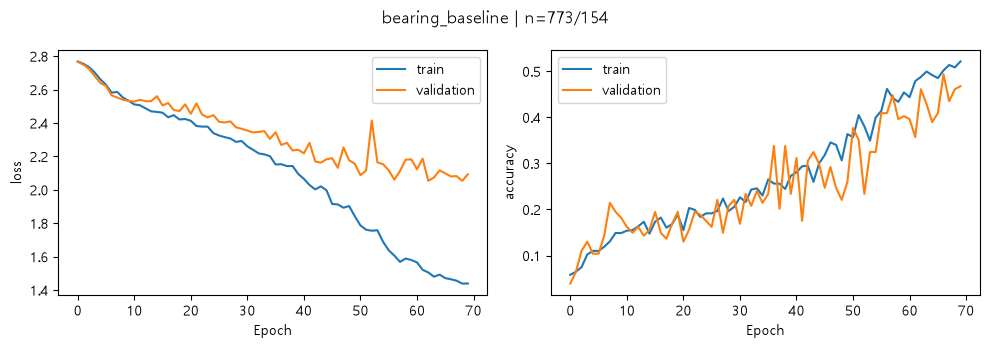

베어링 기준 CNN 실제 학습 완료. 최종 홀드아웃 비교는 노트북 02에서 수행한다.


In [9]:
br_baseline,br_baseline_meta=train_bearing_model("bearing_cnn_baseline")
br_baseline.summary()
br_plot_history(br_baseline_meta,"bearing_baseline")
br_base_validation=br_baseline.predict(BR_X_VALID,batch_size=BR_BATCH_SIZE,verbose=0)
save_json(BR_OUT/"baseline_validation.json",dict(
    accuracy=float(accuracy_score(BR_Y_VALID,br_base_validation.argmax(1))),
    macro_f1=float(f1_score(BR_Y_VALID,br_base_validation.argmax(1),labels=range(16),
                          average="macro",zero_division=0)),run_mode=RUN_MODE))
print("베어링 기준 CNN 실제 학습 완료. 최종 홀드아웃 비교는 노트북 02에서 수행한다.")